# Beach bird detection — CNN

Dataset: Beach Bird Detection v1.0 (512×512 images).

A small CNN (Conv, BatchNorm, ReLU) predicts a bird-score map. Peaks on that map become boxes. This is not a YOLO model. The label files use YOLO text (`class cx cy w h`) because that is the dataset format.

The weights file is not part of this notebook. Training this network produces a checkpoint. The cell **Measured mAP@0.5** was executed on the validation set, and its printed output is that run.

**mAP@0.5:** a predicted box counts as correct only when it overlaps a real bird by at least half (IoU ≥ 0.5). The **0.5 is that overlap cutoff**. It is not a score the model is supposed to reach.

In [1]:
from pathlib import Path
import os

def find_root(start):
    for p in [start, *start.parents]:
        if (p / "dataset").is_dir() and (p / "trials").is_dir():
            return p
    return start

ROOT = find_root(Path.cwd().resolve())

def first_existing(paths):
    for p in paths:
        if p and Path(p).exists():
            return str(Path(p))
    return None

DATA = first_existing([
    os.environ.get("BIRD_DATA"),
    ROOT / "dataset" / "beach-bird" / "Beach Bird Detection Dataset v1.0",
    ROOT / "dataset" / "Beach Bird Detection Dataset v1.0",
])
WEIGHTS = first_existing([
    os.environ.get("BIRD_WEIGHTS"),
    ROOT / "trials" / "runs" / "tune-512-clean.pt",
])
print("dataset found:", DATA is not None)
print("weights found:", WEIGHTS is not None)
print("The weights file is a training result. This notebook does not ship it.")

dataset found: True
weights found: True
The weights file is a training result. This notebook does not ship it.


In [2]:
%matplotlib inline
import math
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

print("torch", torch.__version__)
print("DATA exists:", bool(DATA) and os.path.isdir(DATA))
print("WEIGHTS exists:", bool(WEIGHTS) and os.path.isfile(WEIGHTS))

torch 2.13.0+cpu
DATA exists: True
WEIGHTS exists: True


## 1. Load labels

Each label file has lines: `class cx cy w h` (YOLO text format). We convert those to `[x, y, w, h]` in pixels.

In [3]:
IMG_SIZE = 512

def load_split(split):
    img_dir = os.path.join(DATA, "images", split)
    lbl_dir = os.path.join(DATA, "labels", split)
    items = []
    for name in sorted(os.listdir(lbl_dir)):
        if not name.endswith(".txt"):
            continue
        boxes = []
        with open(os.path.join(lbl_dir, name)) as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                _, cx, cy, w, h = line.split()
                cx, cy, w, h = float(cx) * IMG_SIZE, float(cy) * IMG_SIZE, float(w) * IMG_SIZE, float(h) * IMG_SIZE
                boxes.append([cx - w / 2, cy - h / 2, w, h])
        img_path = os.path.join(img_dir, name.replace(".txt", ".jpg"))
        items.append((img_path, np.array(boxes, dtype=np.float32).reshape(-1, 4)))
    return items

train = load_split("train")
val = load_split("val")
print("train", len(train), "images,", sum(len(b) for _, b in train), "boxes")
print("val  ", len(val), "images,", sum(len(b) for _, b in val), "boxes")

train 1369 images, 8663 boxes
val   291 images, 1843 boxes


## 2. Show some ground-truth boxes (green)

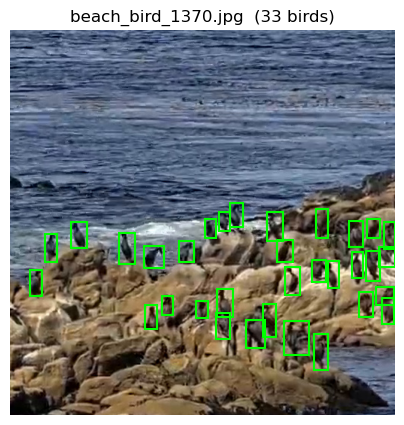

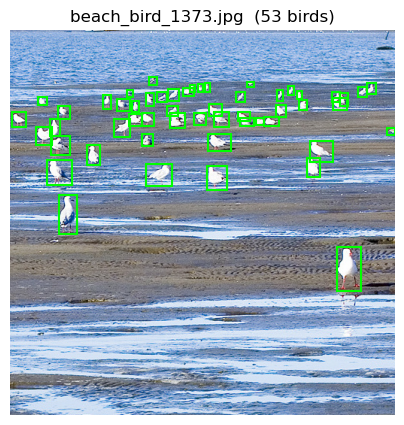

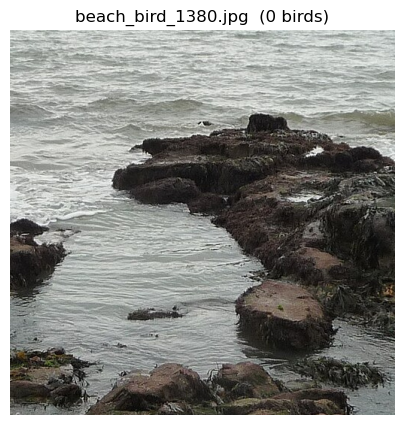

In [4]:
def show_boxes(img_path, boxes, color="lime", title=""):
    im = np.array(Image.open(img_path).convert("RGB"))
    plt.figure(figsize=(5, 5))
    plt.imshow(im)
    ax = plt.gca()
    for x, y, w, h in boxes:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=1.5))
    plt.title(title or os.path.basename(img_path))
    plt.axis("off")
    plt.show()

for i in [0, 3, 10]:
    path, boxes = val[i]
    show_boxes(path, boxes, title=f"{os.path.basename(path)}  ({len(boxes)} birds)")

## 3. Small CNN

Conv → BatchNorm → ReLU (stride 2), upsample, then 3 heads: score map, size, offset.

In [5]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        def block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, stride=2, padding=1),
                nn.BatchNorm2d(out_c),
                nn.ReLU(inplace=True),
            )
        self.enc = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, 128))
        self.dec = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(inplace=True),
        )
        self.hm = nn.Conv2d(32, 1, 1)   # bird score
        self.wh = nn.Conv2d(32, 2, 1)   # width, height
        self.off = nn.Conv2d(32, 2, 1)  # centre offset

    def forward(self, x):
        x = self.dec(self.enc(x))
        return self.hm(x), self.wh(x), self.off(x)

model = Net()
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 190341


## 4. Load a checkpoint, if one was trained

This file is the saved result of training the CNN above. The notebook works as a description of the model without it. The measurement cell needs it only so it can score the run we already trained.

In [6]:
if not WEIGHTS:
    raise FileNotFoundError(
        "No checkpoint next to this project. Train the CNN to produce one. "
        "The notebook does not download weights."
    )
ckpt = torch.load(WEIGHTS, map_location="cpu", weights_only=False)
model.load_state_dict(ckpt["state"])
model.eval()
print(
    "loaded a trained checkpoint:",
    f"epoch {ckpt.get('epoch')}, input {ckpt.get('input')},",
    "stored val mAP", round(float(ckpt.get("map", -1)), 4),
)

loaded a trained checkpoint: epoch 5, input 512, stored val mAP 0.252


## 5. Measured mAP@0.5

This cell scores every validation image. The printout is the answer: what the 0.5 means, and the number this checkpoint actually gets.

In [7]:
def read_tensor(path):
    im = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.array(im, dtype=np.float32) / 255.0
    return torch.from_numpy(arr).permute(2, 0, 1)

def box_iou(a, b):
    aw, ah, bw, bh = a[2], a[3], b[2], b[3]
    if min(aw, ah, bw, bh) <= 0:
        return 0.0
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[0] + aw, b[0] + bw), min(a[1] + ah, b[1] + bh)
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    den = aw * ah + bw * bh - inter
    return inter / den if den > 0 else 0.0

def score_detections(records, iou_thresh=0.5):
    """Average precision. A box is a hit only when IoU with an unused bird is at least iou_thresh."""
    flat, n_gt, tp = [], 0, 0
    for preds, gts in records:
        n_gt += len(gts)
        used = [False] * len(gts)
        for box, sc in sorted(preds, key=lambda t: -t[1]):
            best, best_iou = -1, iou_thresh
            for j, g in enumerate(gts):
                if used[j]:
                    continue
                v = box_iou(box, g)
                if v >= best_iou:
                    best, best_iou = j, v
            hit = best >= 0
            if hit:
                used[best] = True
                tp += 1
            flat.append((sc, hit))
    if n_gt == 0:
        return 1.0, 1.0
    if not flat:
        return 0.0, 0.0
    flat.sort(key=lambda t: -t[0])
    prec, seen = [], 0
    for i, (_sc, hit) in enumerate(flat):
        seen += hit
        prec.append(seen / (i + 1))
    for i in range(len(prec) - 2, -1, -1):
        prec[i] = max(prec[i], prec[i + 1])
    ap = sum(p for (_sc, hit), p in zip(flat, prec) if hit) / n_gt
    return ap, tp / n_gt

def decode_boxes(hm, wh, off, thr, topk):
    score = hm[0]
    pooled = F.max_pool2d(score[None, None], 3, 1, 1)[0, 0]
    peaks = (score == pooled) & (score > thr)
    ys, xs = torch.where(peaks)
    scores = score[ys, xs]
    if len(scores) > topk:
        scores, idx = torch.topk(scores, topk)
        ys, xs = ys[idx], xs[idx]
    stride = 4
    boxes = []
    for y, x, s in zip(ys, xs, scores):
        bw = math.exp(wh[0, y, x].item()) * IMG_SIZE
        bh = math.exp(wh[1, y, x].item()) * IMG_SIZE
        cx = (x.item() + off[0, y, x].item()) * stride
        cy = (y.item() + off[1, y, x].item()) * stride
        boxes.append(([cx - bw / 2, cy - bh / 2, bw, bh], float(s)))
    return boxes

@torch.no_grad()
def validation_map(thr, topk):
    records = []
    for s in range(0, len(val), 4):
        batch = val[s:s + 4]
        x = torch.stack([read_tensor(p) for p, _ in batch])
        hm, wh, off = model(x)
        hm = torch.sigmoid(hm)
        for i in range(len(batch)):
            records.append((decode_boxes(hm[i], wh[i], off[i], thr, topk), batch[i][1]))
    return score_detections(records)

ap_loose, rec_loose = validation_map(0.02, 500)
ap_default, rec_default = validation_map(0.10, 100)
n_birds = sum(len(b) for _, b in val)

print("What mAP@0.5 means")
print("A predicted box counts as correct only when it overlaps a labelled bird by at least half.")
print("The 0.5 is that overlap cutoff (IoU). It is not the number the metric is supposed to return.")
print()
print(f"Validation set: {len(val)} images, {n_birds} birds")
print(f"mAP@0.5   score > 0.02, up to 500 boxes: {ap_loose:.3f}    recall {rec_loose:.3f}")
print(f"mAP@0.5   score > 0.10, up to 100 boxes: {ap_default:.3f}    recall {rec_default:.3f}")
print()
print("Where the weights come from")
print("They are this CNN after training. This notebook does not contain the file, and it is not a downloaded YOLO weight.")
print(
    f"The checkpoint records epoch {ckpt.get('epoch')}, input {ckpt.get('input')}, "
    f"stored val mAP {float(ckpt.get('map')):.3f}."
)
print("Training the same network again is a new run. About 0.16 from scratch, and above 0.20 with augmentation, is that other run.")

What mAP@0.5 means
A predicted box counts as correct only when it overlaps a labelled bird by at least half.
The 0.5 is that overlap cutoff (IoU). It is not the number the metric is supposed to return.

Validation set: 291 images, 1843 birds
mAP@0.5   score > 0.02, up to 500 boxes: 0.252    recall 0.593
mAP@0.5   score > 0.10, up to 100 boxes: 0.242    recall 0.474

Where the weights come from
They are this CNN after training. This notebook does not contain the file, and it is not a downloaded YOLO weight.
The checkpoint records epoch 5, input 512, stored val mAP 0.252.
Training the same network again is a new run. About 0.16 from scratch, and above 0.20 with augmentation, is that other run.


## 6. Predict boxes from the score map

Local peaks on the heatmap become red boxes.

In [8]:
def predict(path, thr=0.1):
    with torch.no_grad():
        hm, wh, off = model(read_tensor(path).unsqueeze(0))
        hm = torch.sigmoid(hm)
        return decode_boxes(hm[0], wh[0], off[0], thr, 100)

boxes = predict(val[0][0])
print("predictions on first val image:", len(boxes))

predictions on first val image: 43


## 7. Show predictions

Green = ground truth, red = prediction.

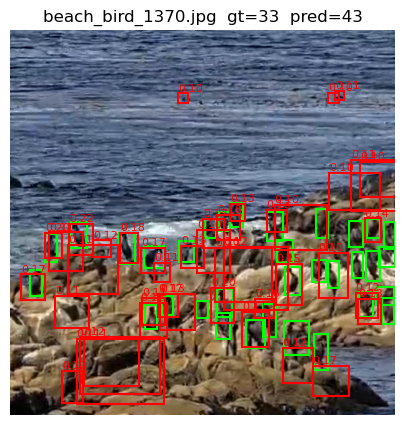

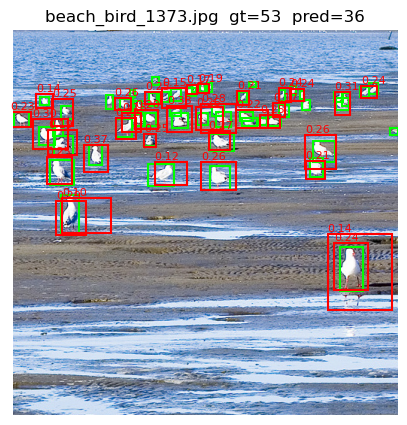

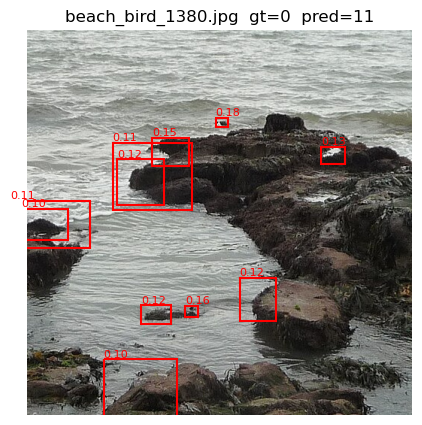

In [9]:
def show_pred(i):
    path, gts = val[i]
    preds = predict(path)
    im = np.array(Image.open(path).convert("RGB"))
    plt.figure(figsize=(5, 5))
    plt.imshow(im)
    ax = plt.gca()
    for x, y, w, h in gts:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=1.5))
    for (x, y, w, h), s in preds:
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1.5))
        ax.text(x, max(0, y - 3), f"{s:.2f}", color="red", fontsize=8)
    plt.title(f"{os.path.basename(path)}  gt={len(gts)}  pred={len(preds)}")
    plt.axis("off")
    plt.show()

show_pred(0)
show_pred(3)
show_pred(10)